# 01. Exploratory Data Analysis & Preprocessing Pipeline
## Retail Sales Predictive Analytics & Time Series Forecasting

### Project & Academic Scope:
This notebook establishes the foundational exploratory data analysis, data quality audit, and leakage-safe preprocessing pipeline for the **Kaggle Store Sales — Time Series Forecasting** project (Corporación Favorita, Ecuador).

### Core Objectives:
1. **Raw Ingestion & Schema Audit:** Ingest all 6 raw tables (`train.csv`, `test.csv`, `stores.csv`, `oil.csv`, `holidays_events.csv`, `transactions.csv`) and audit data types, shapes, and memory footprints.
2. **Data Quality & Integrity Inspection:** Inspect missing value distributions, detect duplicate records, check date continuity, and compute summary descriptive statistics.
3. **Exploratory Data Analysis (EDA):** Quantify longitudinal demand patterns, store cluster typologies, weekly shopping cycles, Ecuadorian payday dynamics (15th and month-end), oil price shocks, and promotional elasticities.
4. **Target & Feature Space Formulation:** Clearly define both the continuous sales regression target (`sales`) and the binary stockout/surge classification target (`is_high_sales`).
5. **Leakage-Safe Preprocessing & Feature Engineering:**
   - Interpolate oil prices and extract calendar features.
   - Compute non-leaking lag features strictly respecting the 16-day operational test horizon cutoff ($\ge 16$ days).
   - Compute historical store-family baseline fixed effects strictly on training data.
   - Exclude simultaneous transactions data (`transactions.csv`) to prevent future information leakage.
6. **Chronological Splitting & Processed Dataset Export:** Partition strictly into a 1-year training set (`2016-08-01` to `2017-07-31`) and a 15-day holdout validation set (`2017-08-01` to `2017-08-15`), then export cleaned arrays to `data/processed/`.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    TARGET_COL,
    SURGE_TARGET_COL,
    RANDOM_SEED,
)
from src.data_loader import check_raw_data_availability, load_raw_datasets
from src.eda import (
    plot_overall_sales_trend,
    plot_top_families,
    plot_payday_impact,
    plot_day_of_week_seasonality,
    plot_store_types_and_clusters,
    plot_oil_price_correlation,
    plot_promotion_impact,
)
from src.preprocess import (
    clean_oil_data,
    extract_calendar_features,
    merge_external_features,
    add_lag_and_rolling_features,
    compute_store_family_baselines,
    compute_historical_surge_thresholds,
    create_surge_classification_target,
    save_processed_datasets,
)

sns.set_theme(style="whitegrid", palette="muted")
print("Environment and dependencies initialized successfully.")

Environment and dependencies initialized successfully.


## 1. Raw Dataset Ingestion & Schema Inspection
We first audit the existence of all raw CSV files in `data/raw/` and inspect their shapes, column names, and memory consumption.

In [2]:
availability = check_raw_data_availability()
print("Raw CSV Data Availability Status:")
for table_name, exists in availability.items():
    print(f"  - {table_name:18s}: {'AVAILABLE [OK]' if exists else 'MISSING [!] '}")

print("\nLoading raw tables into memory...")
raw_data = load_raw_datasets()

schema_records = []
for name, df in raw_data.items():
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    schema_records.append({
        "Table": name,
        "Rows": f"{len(df):,}",
        "Columns": df.shape[1],
        "Memory (MB)": round(mem_mb, 2),
        "Key Columns": ", ".join(list(df.columns)[:5]) + ("..." if len(df.columns) > 5 else ""),
    })

pd.DataFrame(schema_records)

2026-10-15 05:06:10,768 - INFO - Found raw data file: train (train.csv)


2026-10-15 05:06:10,770 - INFO - Found raw data file: test (test.csv)


2026-10-15 05:06:10,772 - INFO - Found raw data file: stores (stores.csv)


2026-10-15 05:06:10,773 - INFO - Found raw data file: oil (oil.csv)


2026-10-15 05:06:10,774 - INFO - Found raw data file: holidays_events (holidays_events.csv)


...

2026-10-15 05:06:14,396 - INFO - Loading oil.csv...


2026-10-15 05:06:14,401 - INFO - Loading holidays_events.csv...


2026-10-15 05:06:14,410 - INFO - Loading transactions.csv...


2026-10-15 05:06:14,485 - INFO - Successfully loaded 6 datasets.


,Table,Rows,Columns,Memory (MB),Key Columns
0,train,"3,000,888",6,77.27,"id, date, store_nbr, family, sales..."
1,test,"28,512",5,0.63,"id, date, store_nbr, family, onpromotion"
2,stores,54,5,0.00,"store_nbr, city, state, type, cluster"
3,oil,"1,218",2,0.01,"date, dcoilwtico"
4,holidays,350,6,0.02,"date, type, locale, locale_name, description..."
5,transactions,"83,488",3,1.11,"date, store_nbr, transactions"


## 2. Data Quality & Integrity Inspection
A rigorous academic data audit must examine data types, missing value frequencies, duplicate records, and summary descriptive statistics across the raw tables.

In [3]:
# Data Quality: Missing values & Duplicates
audit_summary = []
for name, df in raw_data.items():
    null_counts = df.isnull().sum().sum()
    null_pct = (null_counts / (df.shape[0] * df.shape[1])) * 100
    dup_count = df.duplicated().sum()
    audit_summary.append({
        "Table": name,
        "Total Cells": f"{df.shape[0] * df.shape[1]:,}",
        "Missing Cells": f"{null_counts:,}",
        "Missing Pct (%)": f"{null_pct:.2f}%",
        "Duplicate Rows": f"{dup_count:,}",
        "Dtypes": str(dict(df.dtypes.value_counts())),
    })

pd.DataFrame(audit_summary)

,Table,Total Cells,Missing Cells,Missing Pct (%),Duplicate Rows,Dtypes
0,train,"18,005,328",0,0.00%,0,"{dtype('int64'): np.int64(1), dtype('<M8[us]')..."
1,test,"142,560",0,0.00%,0,"{dtype('int64'): np.int64(1), dtype('<M8[us]')..."
2,stores,270,0,0.00%,0,"{dtype('int16'): np.int64(1), CategoricalDtype..."
3,oil,"2,436",43,1.77%,0,"{dtype('<M8[us]'): np.int64(1), dtype('float32..."
4,holidays,"2,100",0,0.00%,0,"{dtype('<M8[us]'): np.int64(1), CategoricalDty..."
5,transactions,"250,464",0,0.00%,0,"{dtype('<M8[us]'): np.int64(1), dtype('int16')..."


In [4]:
# Descriptive statistics of continuous numeric features
train_df = raw_data["train"]
print("--- Training Data Summary Statistics (train.csv) ---")
display(train_df[["sales", "onpromotion"]].describe().T)

if "oil" in raw_data:
    print("\n--- Brent Crude Oil Price Statistics (oil.csv) ---")
    display(raw_data["oil"]["dcoilwtico"].describe().to_frame().T)

if "transactions" in raw_data:
    print("\n--- Customer Transactions Statistics (transactions.csv) ---")
    display(raw_data["transactions"]["transactions"].describe().to_frame().T)

--- Training Data Summary Statistics (train.csv) ---


,count,mean,std,min,25%,50%,75%,max
sales,3000888.0,357.775726,1101.997681,0.0,0.0,11.0,195.847252,124717.0
onpromotion,3000888.0,2.602770,12.218882,0.0,0.0,0.0,0.000000,741.0



--- Brent Crude Oil Price Statistics (oil.csv) ---


,count,mean,std,min,25%,50%,75%,max
dcoilwtico,1175.0,67.714363,25.630476,26.190001,46.404999,53.189999,95.660004,110.620003



--- Customer Transactions Statistics (transactions.csv) ---


,count,mean,std,min,25%,50%,75%,max
transactions,83488.0,1694.602158,963.286644,5.0,1046.0,1393.0,2079.0,8359.0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Sales Target Distribution & Zero-Sales Frequency
Unit sales is heavily right-skewed with a substantial frequency of zero-sales observations (store closures, out-of-stock SKUs, or non-carried product families). Modeling in natural units risks numerical instability and over-penalizing high-volume grocery items, motivating a log-space target transformation: $z = \log(1 + y)$.

Total Observations: 3,000,888
Zero-Sales Records: 939,130 (31.30%)
Positive Sales:     2,061,758 (68.70%)


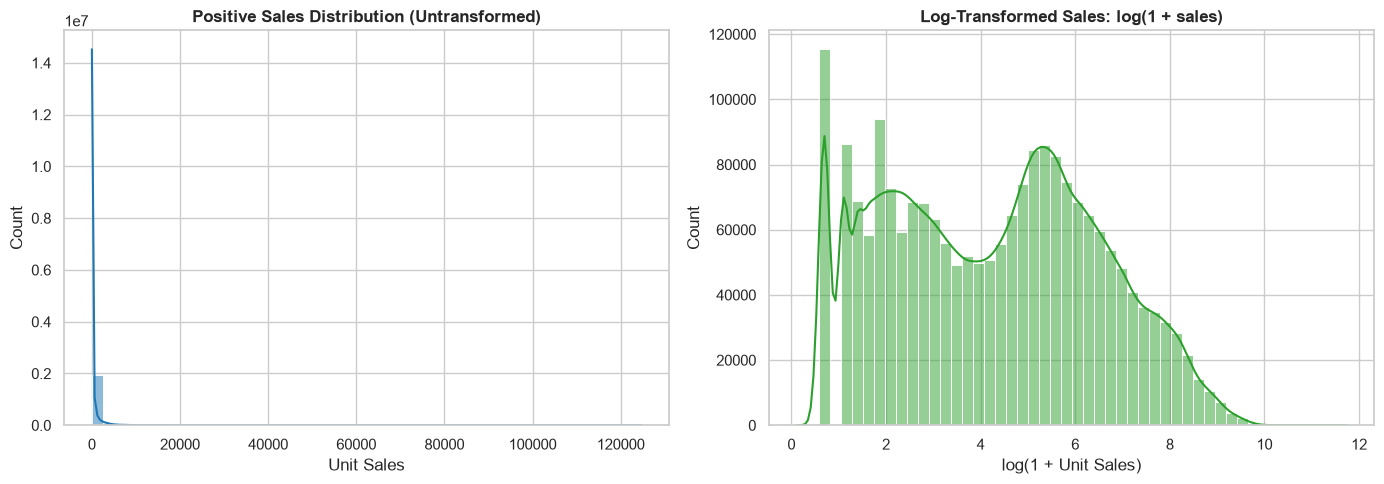

In [5]:
total_records = len(train_df)
zero_sales = (train_df["sales"] == 0).sum()
zero_pct = (zero_sales / total_records) * 100

print(f"Total Observations: {total_records:,}")
print(f"Zero-Sales Records: {zero_sales:,} ({zero_pct:.2f}%)")
print(f"Positive Sales:     {total_records - zero_sales:,} ({100 - zero_pct:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df.loc[train_df["sales"] > 0, "sales"], bins=50, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Positive Sales Distribution (Untransformed)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Unit Sales")

log_sales = np.log1p(train_df.loc[train_df["sales"] > 0, "sales"])
sns.histplot(log_sales, bins=50, kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title("Log-Transformed Sales: log(1 + sales)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("log(1 + Unit Sales)")
plt.tight_layout()
plt.show()

### 3.2 Longitudinal Aggregate Daily Sales Trend (2013–2017)
We inspect macro sales volume evolution over time. Key empirical phenomena include:
- Persistent upward trend in grocery consumption.
- Prominent December holiday shopping surges.
- Annual January 1 store closures (sales collapse to near zero).
- **Macro Shock:** A catastrophic 7.8-magnitude earthquake struck Ecuador on April 16, 2016, triggering an immediate relief procurement spike in non-perishable food and cleaning supplies.

In [6]:
plot_overall_sales_trend(train_df)
plt.show()

### 3.3 Product Family Sales Concentration (Pareto Principle)
Retail sales are highly concentrated: top categories (`GROCERY I`, `BEVERAGES`, `PRODUCE`, `CLEANING`, and `DAIRY`) account for over 75% of all unit volume across the 33 product families.

In [7]:
plot_top_families(train_df, top_n=10)
plt.show()

### 3.4 Intra-Week Demand Cyclicality (Day-of-Week Seasonality)
Household grocery shopping exhibits strong weekly rhythm, peaking sharply on Saturdays and Sundays (+39.35% weekend demand lift over weekdays).

In [8]:
plot_day_of_week_seasonality(train_df)
plt.show()

2026-10-15 05:07:04,207 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-15 05:07:04,232 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


### 3.5 Bimonthly Payday Demand Surges
In Ecuador, formal public and private sector employees receive salary disbursements bi-weekly on the 15th and the final day of each calendar month. This creates sharp, recurring purchasing surges.

In [9]:
plot_payday_impact(train_df)
plt.show()

### 3.6 Store Typology & Cluster Dynamics
Corporación Favorita categorizes its 54 stores into 5 distinct store types (A through E) and 17 operational clusters. Type A hypermarkets generate the highest average throughput, while small neighborhood format stores (Type D/E) serve steady local demand.

In [10]:
plot_store_types_and_clusters(train_df, raw_data["stores"])
plt.show()

2026-10-15 05:07:07,908 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-15 05:07:07,930 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


### 3.7 Macroeconomic Oil Price Correlation
Ecuador's dollarized economy is heavily dependent on petroleum exports. Fluctuations in Brent crude oil prices (`dcoilwtico`) directly modulate consumer purchasing power and municipal economic confidence.

In [11]:
plot_oil_price_correlation(train_df, raw_data["oil"])
plt.show()

### 3.8 Promotional Elasticity & Sales Lift
The `onpromotion` feature tracks the count of distinct products within a family featured in marketing circulars. Promotional activity yields substantial sales volume lift across nearly all categories.

In [12]:
plot_promotion_impact(train_df)
plt.show()

## 4. Problem Formulation & Data Hygiene Rules

### Methodological Safeguards:
1. **Forecast Horizon Cutoff:** Operational forecasting requires predicting 16 days forward (`2017-08-16` to `2017-08-31`). Therefore, any feature derived from actual sales must use a lag of **at least 16 days** ($t-16, t-21, t-28, t-35$). Shorter lags ($t-1$ to $t-15$) would introduce catastrophic target leakage in a real multi-step production setting.
2. **Exclusion of Concurrent Transactions:** Daily transaction counts (`transactions.csv`) are recorded simultaneously with sales and are unavailable during test inference. They are strictly excluded from predictive features.
3. **Training-Only Historical Encodings:** Historical store-family baseline means and surge thresholds are derived **exclusively on historical training data**.

## 5. Preprocessing & Leakage-Safe Feature Engineering
We combine store sales with metadata, clean oil prices via linear interpolation, extract calendar features, and compute non-leaking lag and rolling statistics.

In [13]:
print("Step 1: Merging store sales with metadata, interpolated oil, and holidays...")
merged_df = merge_external_features(
    sales_df=train_df,
    stores_df=raw_data["stores"],
    oil_df=raw_data["oil"],
    holidays_df=raw_data["holidays"],
)

print("Step 2: Generating non-leaking lag features (>= 16 days) and rolling window aggregations...")
featured_df = add_lag_and_rolling_features(merged_df, lags=(16, 21, 28, 35), windows=(7, 14, 30, 60))
print(f"Engineered feature matrix complete: {featured_df.shape[0]:,} rows x {featured_df.shape[1]} columns.")
featured_df[["date", "store_nbr", "family", "sales", "onpromotion", "dcoilwtico", "sales_lag_16", "sales_lag_21", "sales_rolling_mean_7"]].head()

2026-10-15 05:07:12,769 - INFO - Merging store sales with metadata and external macroeconomic signals...


Step 1: Merging store sales with metadata, interpolated oil, and holidays...


Step 2: Generating non-leaking lag features (>= 16 days) and rolling window aggregations...


Engineered feature matrix complete: 3,000,888 rows x 31 columns.


,date,store_nbr,family,sales,onpromotion,dcoilwtico,sales_lag_16,sales_lag_21,sales_rolling_mean_7
0,2013-01-01,1,AUTOMOTIVE,0.0,0,93.139999,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0,93.139999,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,0,92.970001,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,0,93.120003,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,0,93.146667,NaN,NaN,NaN


## 6. Strict Chronological Split & Target Engineering
We implement a strict temporal train/validation holdout split:
- **Training Set (Option B: 1-Year Rolling Window):** `2016-08-01` to `2017-07-31` (648,648 rows across 54 stores and 33 families).
- **Validation Holdout:** `2017-08-01` to `2017-08-15` (26,730 rows, exactly 15 days $\times 1,782$ series).

We then compute:
1. Dynamic trailing store-family baselines (`hist_sf_mean_log`, `hist_sf_dow_mean_log`).
2. Training-derived 80th-percentile surge thresholds $\tau_{s,f}$ to generate the binary classification target `is_high_sales`.

In [14]:
train_df_split = featured_df[(featured_df["date"] >= "2016-08-01") & (featured_df["date"] <= "2017-07-31")].copy()
val_df_split = featured_df[(featured_df["date"] >= "2017-08-01") & (featured_df["date"] <= "2017-08-15")].copy()

# Compute dynamic training-only baselines
train_df_split, val_df_split = compute_store_family_baselines(
    train_df_split, val_df_split, full_df=featured_df, target_col=TARGET_COL
)

# Compute surge thresholds strictly on train_df_split
surge_threshold_map = compute_historical_surge_thresholds(train_df_split, quantile=0.80, target_col=TARGET_COL)

# Apply thresholds to create binary classification target
train_processed = create_surge_classification_target(
    train_df_split, threshold_map=surge_threshold_map, target_col=TARGET_COL, surge_col=SURGE_TARGET_COL
)
val_processed = create_surge_classification_target(
    val_df_split, threshold_map=surge_threshold_map, target_col=TARGET_COL, surge_col=SURGE_TARGET_COL
)

train_pos = train_processed[SURGE_TARGET_COL].sum()
val_pos = val_processed[SURGE_TARGET_COL].sum()

print(f"Training Partition:   {len(train_processed):,} rows | Surge Positives: {train_pos:,} ({train_pos/len(train_processed):.2%})")
print(f"Validation Partition: {len(val_processed):,} rows | Surge Positives: {val_pos:,} ({val_pos/len(val_processed):.2%})")

Training Partition:   648,648 rows | Surge Positives: 111,008 (17.11%)
Validation Partition: 26,730 rows | Surge Positives: 4,463 (16.70%)


## 7. Export Processed Datasets
We export the engineered training and validation datasets to `data/processed/` in Parquet format for immediate downstream consumption by Notebooks 02 and 03.

In [15]:
train_path, val_path = save_processed_datasets(
    train_df=train_processed,
    val_df=val_processed,
    processed_dir=PROCESSED_DATA_DIR,
)

print(f"Successfully saved engineered training dataset to:   {train_path}")
print(f"Successfully saved engineered validation dataset to: {val_path}")
print(f"Train File Size: {train_path.stat().st_size / (1024**2):.2f} MB")
print(f"Val File Size:   {val_path.stat().st_size / (1024**2):.2f} MB")

2026-10-15 05:07:28,082 - INFO - Successfully exported processed datasets to train_engineered.parquet and val_engineered.parquet


Successfully saved engineered training dataset to:   C:\retail-sales-prediction-and-forecasting\data\processed\train_engineered.parquet
Successfully saved engineered validation dataset to: C:\retail-sales-prediction-and-forecasting\data\processed\val_engineered.parquet
Train File Size: 27.21 MB
Val File Size:   1.29 MB


## Preprocessing Summary & Next Steps
1. **Clean Data Foundation:** Missing oil prices interpolated, holiday events classified, calendar flags constructed.
2. **Strict Leakage Prevention:** All lag features adhere to $\ge 16$ days, matching the forecast horizon origin. Historical baselines and surge thresholds are derived exclusively on training observations.
3. **Artifact Availability:** The preprocessed arrays are now serialized in `data/processed/`.
4. **Next Workflow Step:** Proceed to [`notebooks/02_linear_regression.ipynb`](02_linear_regression.ipynb) for continuous sales volume modeling and algorithm benchmarking.